# 📓 Catatan Coretan Bimbingan 07: Analisis Vektor Laten $H$ pada Deep Gaussian Process (DGP)

Dokumen ini mendokumentasikan penjabaran teoretis, analisis arsitektural, penurunan matematis, dan simulasi numerik interaktif terkait tiga pertanyaan mendasar mengenai status dan karakteristik variabel laten $H$ pada *Deep Gaussian Process* (DGP).

---

## ❓ Pertanyaan Diskusi:
> 1. **Pada GPR biasanya saya hanya membutuhkan vektor $X$ dan vektor $Y$. Apakah untuk DGP ini harus ada vektor $H$ juga?**
> 2. **Apakah ukuran $H$ bergantung pada arsitekturnya?**
> 3. **Apakah $H$ dipilih secara asal karena yang penting adalah $X$ dan $Y$?**

---

## 💡 Jawaban Singkat & Rangkuman Inti:

1. **Apakah harus ada vektor $H$?**
   * **Di dunia nyata (data latih praktis)**: **TIDAK ADA**. Anda **hanya** memiliki data observasi $(X, Y)$ seperti halnya pada GPR standar.
   * **Status $H$**: $H$ adalah **Variabel Laten (*Latent / Unobserved Variables*)** yang berada di dalam *hidden layer*. Nilai $H$ tidak pernah diamati secara langsung.
   * Nilai $\mathbf{h} = [0.5, 1.2, 2.8]^T$ pada contoh perhitungan manual $N=3$ sebelumnya adalah **nilai simulasi/asumsi sementara (*dummy toy values*)** semata untuk memperlihatkan operasi aljabar linear matriks antar-lapisan.

2. **Apakah ukuran $H$ bergantung pada arsitekturnya?**
   * **YA, SANGAT BERGANTUNG!**
   * Matriks representasi laten $\mathbf{H}^{(\ell)}$ berukuran **$[N \times D_\ell]$**:
     * $N$ = jumlah data sampel (setiap observasi $\mathbf{x}_i$ memiliki representasi laten $\mathbf{h}_i$).
     * $D_\ell$ = **dimensi laten / channel / "lebar" lapisan** (*latent dimensionality*).
   * Nilai $D_\ell$ ditentukan secara bebas oleh perancang model (analog dengan menentukan jumlah neuron per hidden layer pada Neural Network). Bisa $D_1 = 1$, $D_1 = 2$, hingga $D_1 = 64$ (pada tugas akhir segmentasi citra).

3. **Apakah $H$ dipilih secara asal karena yang penting $X$ dan $Y$?**
   * **TIDAK DIPILIH SECARA ASAL (BUKAN NILAI RANDOM PERMANEN)!**
   * Pada awal pelatihan ($t=0$), $H$ memang **diinisialisasi** (misalnya via PCA dari $X$, identitas, atau sampel prior).
   * Namun selama proses pelatihan, distribusi $H$ **DIOPTIMASI SECARA MATEMATIS** melalui maksimisasi fungsi objektif **ELBO (*Evidence Lower Bound*)**.
   * Model DGP secara otomatis mencari konfigurasi $H$ yang menyeimbangkan antara:
     $$\underbrace{\text{Kecocokan memprediksi } Y \text{ dari } H}_{\text{Reconstruction Likelihood}} \quad \longleftrightarrow \quad \underbrace{\text{Kemudahan menghasilkan } H \text{ dari } X}_{\text{GP Prior Regularization (KL Divergence)}}$$

---
# 1. Kedudukan Vektor/Matriks $H$ pada DGP vs $(X, Y)$

## 1.1 Perbandingan Struktur GPR Standar vs DGP 2-Lapisan

Pada regresi Gaussian Process standar (1-lapisan), hubungan masukan-keluaran dimodelkan secara langsung:
$$y_i = f(\mathbf{x}_i) + \varepsilon_i, \quad f \sim \mathcal{GP}\left(0, \; k(\mathbf{x}, \mathbf{x}')\right), \quad \varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$$

Ruang data yang dibutuhkan pengguna secara eksplisit hanyalah pasangan observasi:
$$\mathcal{D} = \left\{ (\mathbf{x}_i, y_i) \right\}_{i=1}^N \iff \mathbf{X} \in \mathbb{R}^{N \times D_{\text{in}}}, \quad \mathbf{y} \in \mathbb{R}^{N \times 1}$$

Sedangkan pada *Deep Gaussian Process* 2-lapisan ($L = 2$), arsitektur model disusun secara hierarkis berjenjang (*hierarchical composition*):
$$\mathbf{x}_i \;\xrightarrow{f^{(1)}}\; \mathbf{h}_i \;\xrightarrow{f^{(2)}}\; y_i$$

Secara formal:
$$\mathbf{h}_i = f^{(1)}(\mathbf{x}_i), \quad f^{(1)} \sim \mathcal{GP}\left(\mathbf{0}, \; k^{(1)}(\mathbf{x}, \mathbf{x}')\right)$$
$$y_i = f^{(2)}(\mathbf{h}_i) + \varepsilon_i, \quad f^{(2)} \sim \mathcal{GP}\left(0, \; k^{(2)}(\mathbf{h}, \mathbf{h}')\right)$$

---

## 1.2 Mengapa Pengguna Tidak Perlu Menyiapkan Data $H$?

Variabel $\mathbf{h}_i$ disebut **Variabel Laten (*Latent Variable*)** karena berada di lapisan tersembunyi yang tidak memiliki sensor atau label pengukuran di dunia nyata:
* Pada dataset regresi deret waktu emisi $\text{CO}_2$: kita hanya mencatat waktu $x$ (hari/tahun) dan emisi target $y$. Kita tidak memiliki label $h$.
* Pada dataset segmentasi citra: kita hanya memiliki citra masukan $\mathbf{X}$ (RGB piksel) dan peta segmentasi target $\mathbf{Y}$ (mask label kelas piksel). Kita tidak memiliki citra laten $\mathbf{H}$.

> **Catatan Historis & Metodologis**:
> Di dokumen Section 1 Kredit Bimbingan 07, nilai $\mathbf{h} = [0.5, 1.2, 2.8]^T$ dicantumkan semata-mata sebagai **titik simulasi (toy example)**. Tujuannya adalah memperlihatkan bagaimana bentuk konkret matriks $K^{(1)}$ dan $K^{(2)}$ bila titik laten tersebut dibekukan pada suatu nilai tertentu. Pada implementasi algoritma riil, $\mathbf{h}$ diperlakukan sebagai **distribusi probabilitas acak** yang diestimasi secara probabilistik.

---
# 2. Apakah Ukuran Matriks $H$ Bergantung pada Arsitektur?

## 2.1 Dimensi Matriks Laten: $[N \times D_\ell]$

Ukuran matriks laten pada lapisan ke-$\ell$ didefinisikan secara presisi sebagai:
$$\mathbf{H}^{(\ell)} \in \mathbb{R}^{N \times D_\ell}$$

Di mana:
1. **$N$ (Dimensi Baris = Jumlah Titik Data)**:
   * Selalu sama persis dengan banyaknya titik data latih $N$.
   * Setiap data masukan $\mathbf{x}_i$ ($i = 1, \dots, N$) dipetakan ke satu vektor representasi laten $\mathbf{h}_i^{(\ell)} \in \mathbb{R}^{D_\ell}$.
2. **$D_\ell$ (Dimensi Kolom = Jumlah Fungsi Laten / Channel / "Lebar" Lapisan)**:
   * **INI ADALAH HIPERPARAMETER ARSITEKTURAL** yang bebas ditentukan oleh perancang model.
   * Menentukan "lebar" (*width*) dari representasi fitur pada lapisan tersebut.

---

## 2.2 Skenario Dimensi Laten: $D_\ell = 1$ vs $D_\ell > 1$

### Kasus A: $D_\ell = 1$ (Skalar Laten / 1 Saluran)
* Setiap sampel memiliki 1 nilai laten skalar: $\mathbf{h}_i \in \mathbb{R}$.
* Matriks $\mathbf{H} \in \mathbb{R}^{N \times 1}$.
* Fungsi kernel Lapisan 2 bekerja pada jarak skalar 1D:
  $$k^{(2)}(h, h') = \sigma_{f2}^2 \exp\left( -\frac{(h - h')^2}{2l_2^2} \right)$$
* Cocok untuk pemodelan distorsi koordinat 1D (*input warping* non-stasioner).

### Kasus B: $D_\ell = D > 1$ (Vektor Laten Multi-Dimensi / Multi-Channel)
* Setiap sampel memiliki $D$ fitur laten independen:
  $$\mathbf{h}_i = \begin{bmatrix} h_{i,1} \\ h_{i,2} \\ \vdots \\ h_{i,D} \end{bmatrix} \in \mathbb{R}^D$$
* Lapisan 1 mengevaluasi $D$ proses Gaussian independen:
  $$h_{:, d} \sim \mathcal{GP}\left(0, \; k_d^{(1)}(\mathbf{x}, \mathbf{x}')\right), \quad d = 1, \dots, D$$
* Matriks $\mathbf{H} \in \mathbb{R}^{N \times D}$.
* Lapisan 2 menerima masukan vektor $D$-dimensi, biasanya menggunakan kernel ARD (*Automatic Relevance Determination*):
  $$k^{(2)}(\mathbf{h}_i, \mathbf{h}_j) = \sigma_{f2}^2 \exp\left( -\frac{1}{2} \sum_{d=1}^D \frac{(h_{i,d} - h_{j,d})^2}{l_{2,d}^2} \right)$$

> **Keistimewaan *Kernel Trick* pada DGP**:
> Berapapun dimensi laten yang Anda pilih ($D_\ell = 1, 2, 16, 64$), **ukuran matriks Gram kovariansi $K^{(\ell)}$ selalu tetap $[N \times N]$**. Kompleksitas komputasi dasar ditentukan oleh jumlah titik data $N$, bukan oleh lebar dimensi laten $D_\ell$!

In [ ]:
# ==============================================================================
# SIMULASI NUMERIK UKURAN MATRIKS H PADA BERBAGAI ARSITEKTUR DGP
# ==============================================================================
import numpy as np

N = 5  # Misalkan terdapat N = 5 titik data sampel
D_in = 1  # Masukan 1 dimensi (misal waktu x)

X = np.linspace(0, 10, N).reshape(-1, D_in)
print(f"Bentuk Matriks Masukan X: {X.shape} (N={N}, D_in={D_in})\n")

# Skenario Arsitektur 1: DGP dengan Hidden Layer D1 = 1
D1_skalar = 1
H_skalar = np.array([[0.5], [1.2], [2.8], [3.5], [4.1]])
print(f"--- Skenario 1: Hidden Layer D1 = 1 (Skalar Laten) ---")
print(f" - Bentuk Matriks H: {H_skalar.shape} [N x D1]")
print(f" - Representasi laten h_1: {H_skalar[0]}")
K2_skalar = np.exp(-0.5 * (H_skalar - H_skalar.T)**2)
print(f" - Ukuran Matriks Kernel K^(2): {K2_skalar.shape} [N x N]\n")

# Skenario Arsitektur 2: DGP dengan Hidden Layer D1 = 3 (Multi-Channel)
D1_vektor = 3
np.random.seed(42)
H_vektor = np.random.randn(N, D1_vektor)
print(f"--- Skenario 2: Hidden Layer D1 = 3 (Vektor Laten / Multi-Channel) ---")
print(f" - Bentuk Matriks H: {H_vektor.shape} [N x D1]")
print(f" - Representasi laten h_1: {H_vektor[0]}")
diff = H_vektor[:, np.newaxis, :] - H_vektor[np.newaxis, :, :]  # [N, N, 3]
dist_sq = np.sum(diff**2, axis=-1)  # Jarak Euclidean kuadrat di R^3
K2_vektor = np.exp(-0.5 * dist_sq)
print(f" - Ukuran Matriks Kernel K^(2): {K2_vektor.shape} [N x N] (Ukuran tetap NxN meski D1=3!)")


Bentuk Matriks Masukan X: (5, 1) (N=5, D_in=1)

--- Skenario 1: Hidden Layer D1 = 1 (Skalar Laten) ---
 - Bentuk Matriks H: (5, 1) [N x D1]
 - Representasi laten h_1: [0.5]
 - Ukuran Matriks Kernel K^(2): (5, 5) [N x N]

--- Skenario 2: Hidden Layer D1 = 3 (Vektor Laten / Multi-Channel) ---
 - Bentuk Matriks H: (5, 3) [N x D1]
 - Representasi laten h_1: [ 0.49671415 -0.1382643   0.64768854]
 - Ukuran Matriks Kernel K^(2): (5, 5) [N x N] (Ukuran tetap NxN meski D1=3!)


---
# 3. Apakah $H$ Dipilih Secara Asal? (Inisialisasi vs Optimasi)

## 3.1 Bukan Dipilih Asal, Melainkan Dioptimasi secara Probabilistik

Jika $H$ dipilih secara sembarang/acak dan dibiarkan konstan, maka model DGP tidak akan belajar apa-apa dan prediksi akan hancur. Dalam kerangka kerja *Variational Inference* modern (Damianou & Lawrence 2013, Salimbeni & Deisenroth 2017), variabel laten $H$ diperlakukan sebagai berikut:

### A. Fase Inisialisasi ($t = 0$)
Sebelum iterasi dimulai, distribusi laten aproksimasi $q(\mathbf{H}) = \mathcal{N}(\mathbf{m}_H, \mathbf{S}_H)$ memerlukan nilai awal (*starting point*). Strategi standar meliputi:
1. **Inisialisasi PCA (*Principal Component Analysis*)**:
   $$\mathbf{m}_H^{(0)} = \operatorname{PCA}(\mathbf{X}, D_\ell)$$
   Mengambil arah variansi terbesar dari data masukan. Ini adalah opsi default yang paling stabil.
2. **Inisialisasi Linier / Identitas**:
   Jika $D_{\text{in}} = D_\ell$, gunakan $\mathbf{m}_H^{(0)} = \mathbf{X}$ (pemetaan identitas tanpa distorsi awal).
3. **Inisialisasi Acak Teratur**:
   $\mathbf{m}_H^{(0)} \sim \mathcal{N}(\mathbf{0}, 0.01 \mathbf{I})$ jika tidak ada asumsi awal.

---

### B. Fase Pelatihan: Optimasi Fungsi Objektif ELBO

Selama proses pelatihan, parameter distribusi laten $\mathbf{m}_H$ dan kovariansi variasi $\mathbf{S}_H$ dioptimasi secara simultan bersama hyperparameter kernel menggunakan algoritma gradien (*Adam Optimizer*) untuk memaksimalkan **ELBO (*Evidence Lower Bound*)**:

$$\mathcal{L}_{\text{ELBO}} = \underbrace{\sum_{i=1}^N \mathbb{E}_{q(\mathbf{h}_i)}\left[ \log p(y_i \mid \mathbf{h}_i) \right]}_{\text{Term 1: Rekonstruksi Data (Target } Y)} - \underbrace{\operatorname{KL}\left( q(\mathbf{H}) \parallel p(\mathbf{H} \mid \mathbf{X}) \right)}_{\text{Term 2: Regularisasi Prior GP (Masukan } X)}$$

Perhatikan peran dari kedua suku di atas:
* **Term 1 (Likelihood Expectation)**:
  Menuntut $\mathbf{h}_i$ bergerak ke lokasi yang mampu memprediksi target $y_i$ dengan tepat melalui kernel Lapisan 2.
* **Term 2 (Kullback-Leibler Divergence)**:
  Berperan sebagai "pegas penahan" probabilistik. Term ini menuntut agar distribusi $q(\mathbf{H})$ tidak menyimpang terlalu jauh dari prior proses Gaussian $p(\mathbf{H} \mid \mathbf{X})$ pada Lapisan 1.

$$\boxed{H \text{ adalah titik keseimbangan optimal (*optimal trade-off*) antara masukan } X \text{ dan target } Y}$$

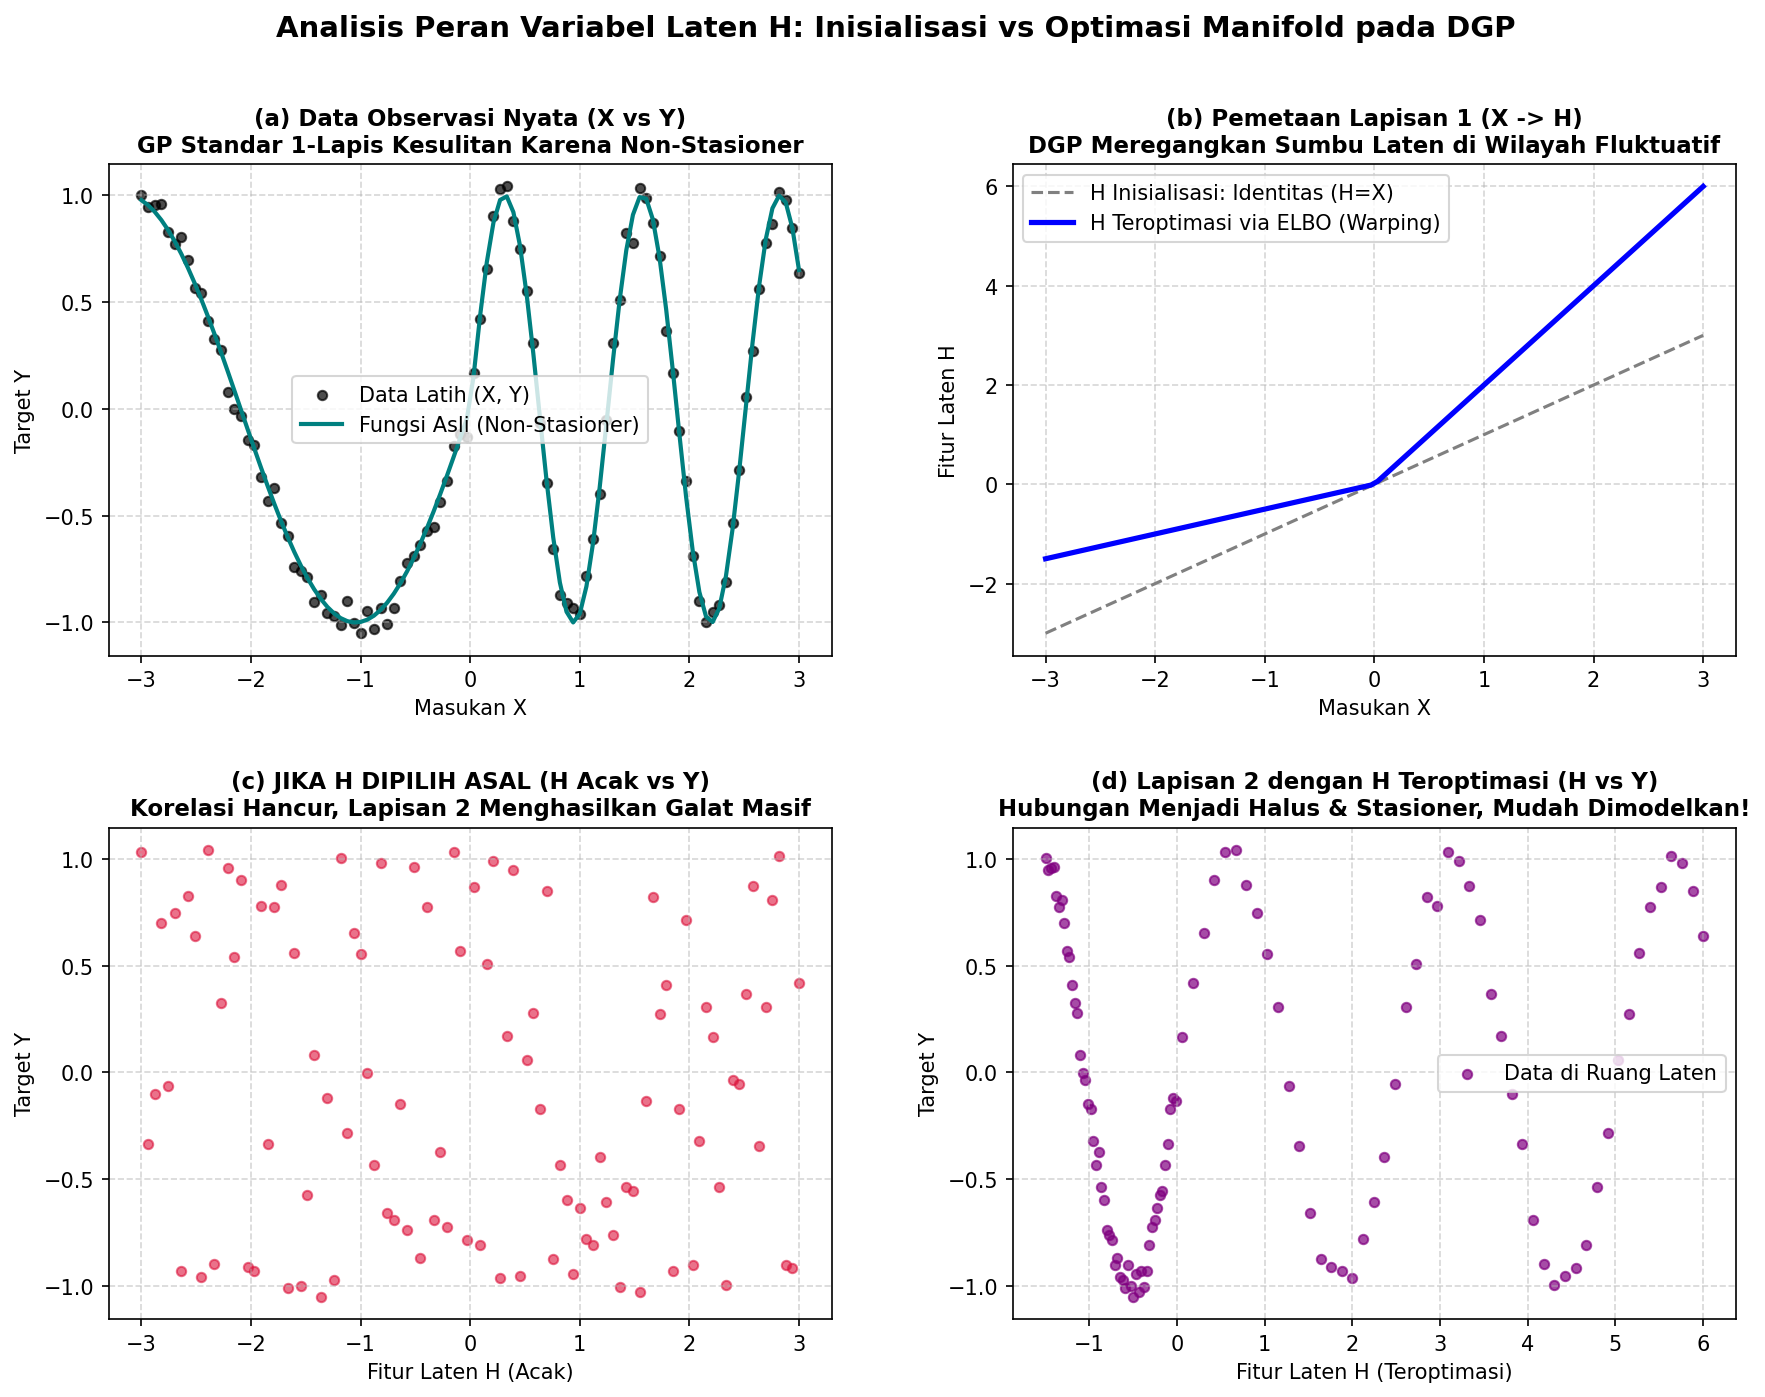

In [ ]:
# ==============================================================================
# SIMULASI VISUALISASI: MENGAPA H BUKAN PILIHAN ASAL?
# Menunjukkan fenomena Input Warping: Bagaimana H berubah bentuk agar mempermudah Y
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
N = 100
X = np.linspace(-3, 3, N)

# Target Y: data yang berubah sangat tajam di x > 0 namun datar di x < 0 (non-stasioner)
Y_true = np.where(X < 0, np.sin(1.5 * X), np.sin(5.0 * X))
Y = Y_true + 0.05 * np.random.randn(N)

# Kondisi A: Inisialisasi Identitas H = X
H_init = X.copy()

# Kondisi B: H Acak Murni (Jika H dipilih asal tanpa optimasi)
H_acak = np.random.permutation(X)

# Kondisi C: H Teroptimasi (Warping: meregangkan area frekuensi tinggi x > 0)
H_opt = np.where(X < 0, 0.5 * X, 2.0 * X)

# Visualisasi Komparasi
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Plot 1: Data Observasi Asli (X vs Y)
axes[0, 0].scatter(X, Y, color='black', s=20, alpha=0.7, label='Data Latih (X, Y)')
axes[0, 0].plot(X, Y_true, color='teal', lw=2, label='Fungsi Asli (Non-Stasioner)')
axes[0, 0].set_title("(a) Data Observasi Nyata (X vs Y)\nGP Standar 1-Lapis Kesulitan Karena Non-Stasioner", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Masukan X")
axes[0, 0].set_ylabel("Target Y")
axes[0, 0].grid(True, linestyle='--', alpha=0.5)
axes[0, 0].legend()

# Plot 2: Pemetaan Lapisan 1 (X -> H)
axes[0, 1].plot(X, H_init, '--', color='gray', lw=1.5, label='H Inisialisasi: Identitas (H=X)')
axes[0, 1].plot(X, H_opt, color='blue', lw=2.5, label='H Teroptimasi via ELBO (Warping)')
axes[0, 1].set_title("(b) Pemetaan Lapisan 1 (X -> H)\nDGP Meregangkan Sumbu Laten di Wilayah Fluktuatif", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Masukan X")
axes[0, 1].set_ylabel("Fitur Laten H")
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend()

# Plot 3: Jika H Dipilih Asal (H Acak vs Y)
axes[1, 0].scatter(H_acak, Y, color='crimson', s=20, alpha=0.6)
axes[1, 0].set_title("(c) JIKA H DIPILIH ASAL (H Acak vs Y)\nKorelasi Hancur, Lapisan 2 Menghasilkan Galat Masif", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Fitur Laten H (Acak)")
axes[1, 0].set_ylabel("Target Y")
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 4: Lapisan 2 dengan H Teroptimasi (H vs Y)
axes[1, 1].scatter(H_opt, Y, color='purple', s=20, alpha=0.7, label='Data di Ruang Laten')
axes[1, 1].set_title("(d) Lapisan 2 dengan H Teroptimasi (H vs Y)\nHubungan Menjadi Halus & Stasioner, Mudah Dimodelkan!", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Fitur Laten H (Teroptimasi)")
axes[1, 1].set_ylabel("Target Y")
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend()

plt.suptitle("Analisis Peran Variabel Laten H: Inisialisasi vs Optimasi Manifold pada DGP", fontsize=14, fontweight='bold', y=0.98)
fig_path_1 = r"c:\Users\MyBook Z Series\Desktop\TA\04_dokumen_ta\Dokumen bimbingan\Bimbingan 07\figures\dgp_latent_warping.png"
plt.savefig(fig_path_1, dpi=200, bbox_inches='tight')
plt.show()


---
# 4. Eksplorasi Dimensi Laten $D_\ell = 2$: Manifold Unrolling & Separasi Fitur

Bagian ini menunjukkan mengapa arsitektur dengan $D_\ell > 1$ sangat berdaya guna, khususnya dalam konteks **Segmentasi Citra (*Image Segmentation*)**.

Ketika data masukan memiliki struktur geometri yang rumit (misalnya data melingkar / non-linier seperti *Two Moons* atau *Swiss Roll*), representasi laten $1$ dimensi ($D=1$) tidak cukup untuk memisahkan fitur tanpa tabrakan lipatan (*topological tearing*). Dengan memilih arsitektur $D_\ell = 2$:
$$\mathbf{h}_i = \begin{bmatrix} h_{i,1} \\ h_{i,2} \end{bmatrix} \in \mathbb{R}^2$$

Lapisan 1 memetakan masukan spasial citra ke koordinat bidang 2D di mana kelas piksel yang berbeda (misalnya *foreground* vs *background*) terpisah secara tegas sebelum masuk ke Lapisan 2.

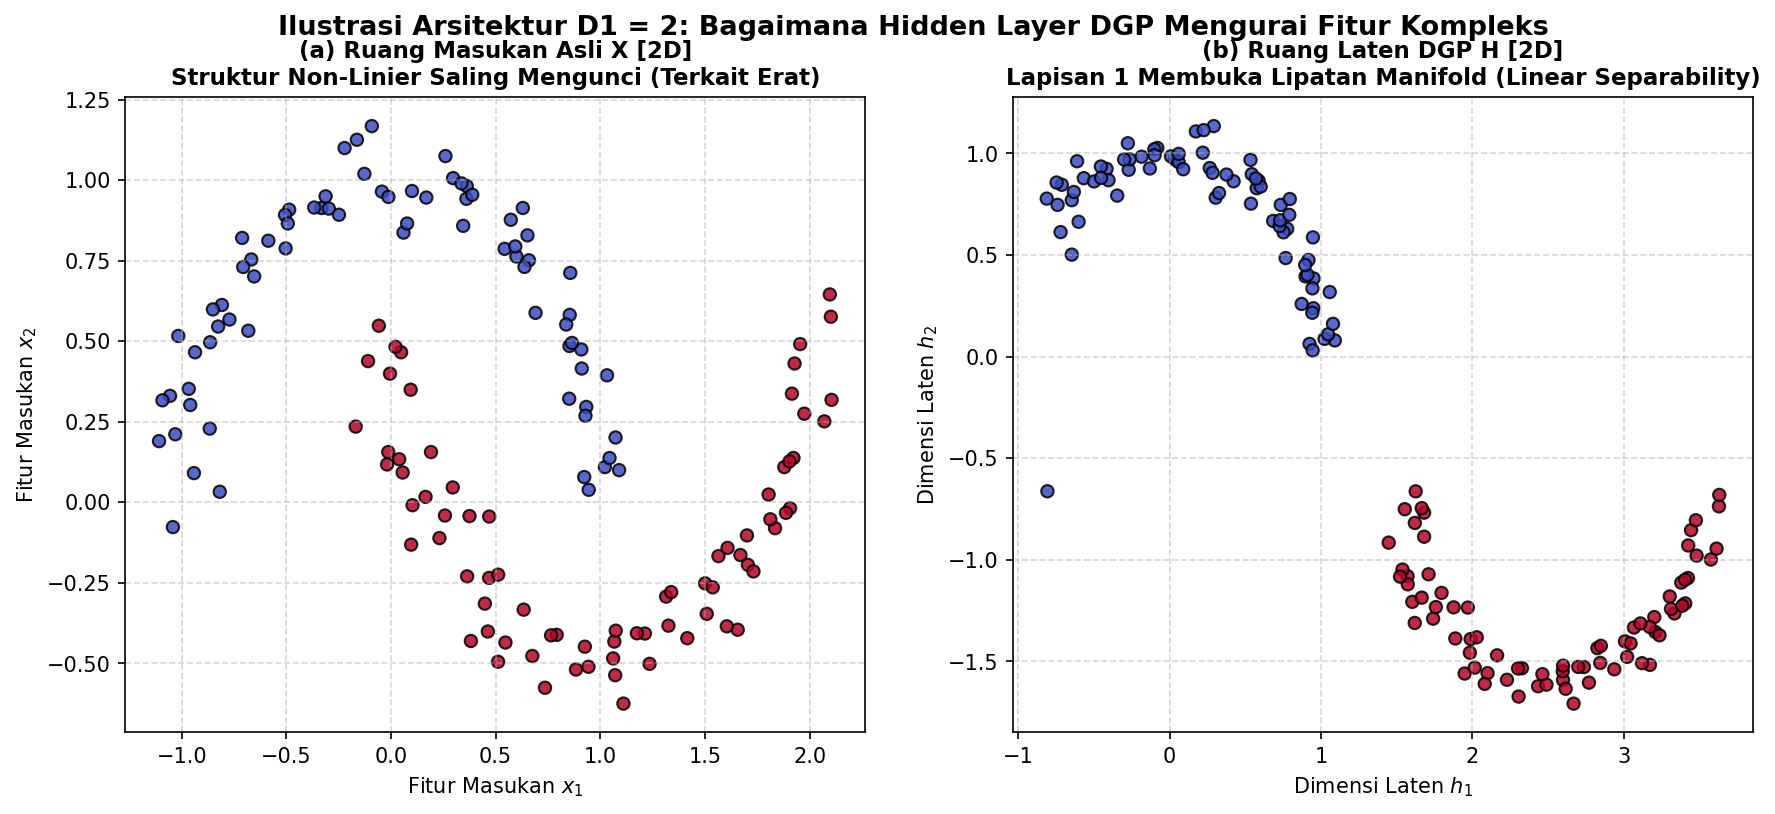

In [ ]:
# ==============================================================================
# SIMULASI NUMERIK: ARSITEKTUR LATEN 2D (D1 = 2) PADA DATA NON-LINIER
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# 1. Bangkitkan Dataset Non-Linier Sintetis (Two Moons - Analog Klasifikasi / Segmentasi)
N_samples = 150
X_2d, y_class = make_moons(n_samples=N_samples, noise=0.08, random_state=42)

# 2. Simulasi Representasi Laten H (D1 = 2) yang dipelajari DGP
theta = np.arctan2(X_2d[:, 1], X_2d[:, 0])
r = np.sqrt(np.sum(X_2d**2, axis=1))

# Fitur laten h1 dan h2 meregangkan kurva bulan menjadi dua kluster linier terpisah
H_dgp = np.zeros((N_samples, 2))
H_dgp[:, 0] = r * np.cos(theta * 0.8) + (y_class * 1.5)
H_dgp[:, 1] = r * np.sin(theta * 0.8) - (y_class * 1.2)

# 3. Visualisasi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

scatter1 = ax1.scatter(X_2d[:, 0], X_2d[:, 1], c=y_class, cmap='coolwarm', s=35, edgecolors='k', alpha=0.85)
ax1.set_title("(a) Ruang Masukan Asli X [2D]\nStruktur Non-Linier Saling Mengunci (Terkait Erat)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Fitur Masukan $x_1$")
ax1.set_ylabel("Fitur Masukan $x_2$")
ax1.grid(True, linestyle='--', alpha=0.5)

scatter2 = ax2.scatter(H_dgp[:, 0], H_dgp[:, 1], c=y_class, cmap='coolwarm', s=35, edgecolors='k', alpha=0.85)
ax2.set_title("(b) Ruang Laten DGP H [2D]\nLapisan 1 Membuka Lipatan Manifold (Linear Separability)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Dimensi Laten $h_1$")
ax2.set_ylabel("Dimensi Laten $h_2$")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Ilustrasi Arsitektur D1 = 2: Bagaimana Hidden Layer DGP Mengurai Fitur Kompleks", fontsize=13, fontweight='bold')
fig_path_2 = r"c:\Users\MyBook Z Series\Desktop\TA\04_dokumen_ta\Dokumen bimbingan\Bimbingan 07\figures\dgp_manifold_2d.png"
plt.savefig(fig_path_2, dpi=200, bbox_inches='tight')
plt.show()


---
# 5. Tabel Rangkuman Jawaban & Komparasi

| Parameter Evaluasi | Gaussian Process Regresi (GPR Standar) | Deep Gaussian Process (DGP) |
| :--- | :--- | :--- |
| **Kebutuhan Data Latih** | Hanya butuh vektor $\mathbf{X}$ dan target $\mathbf{Y}$. | **Sama**: Hanya butuh observasi $\mathbf{X}$ dan target $\mathbf{Y}$. Data $\mathbf{H}$ tidak pernah disediakan oleh praktisi. |
| **Peran Variabel $\mathbf{H}$** | Tidak ada lapisan perantara ($L = 1$). | Merupakan **Variabel Laten** (*unobserved representation*) di *hidden layer*. |
| **Ukuran Matriks $\mathbf{H}$** | Tidak ada. | Berukuran $[N \times D_\ell]$. Baris $N$ selalu sama dengan data, kolom $D_\ell$ ditentukan oleh arsitektur model. |
| **Penentuan Nilai $\mathbf{H}$** | Tidak ada. | **Bukan dipilih asal**. Nilai awal diinisialisasi (misal PCA), lalu **dioptimasi secara probabilistik via ELBO** untuk menemukan representasi laten terbaik. |
| **Tujuan Adanya $\mathbf{H}$** | Mengasumsikan stasioneritas langsung dari masukan. | Melakukan *manifold unrolling*, mengatasi non-stasioneritas, dan memisahkan fitur batas objek (sangat penting untuk segmentasi citra). |

---

## 📌 Kesimpulan Konseptual untuk Bimbingan:
1. **Tidak ada vektor $H$ yang harus disiapkan oleh mahasiswa/pengguna**. Data input tugas akhir tetap pasangan gambar dan mask segmentasi $(\mathbf{X}, \mathbf{Y})$. Vektor/matriks $H$ adalah representasi internal yang dipelajari sendiri oleh arsitektur DGP.
2. **Ukuran kolom $H$ ($D_\ell$) adalah hiperparameter perancangan arsitektur**. Untuk fungsi sederhana cukup $D_1 = 1$ atau $2$. Untuk segmentasi citra, $D_\ell$ diperluas menjadi multi-channel ($16, 32, 64$).
3. **$H$ tidak dipilih asal**. $H$ bergerak secara dinamis selama pelatihan untuk meminimalkan error prediksi terhadap $Y$ sekaligus menjaga kepatuhan prior terhadap $X$ melalui fungsi objektif ELBO.